# Notebook 11: Master Results Summary & Comparative Visualization

**Objective**: Consolidate and visualize all empirical results generated across the OPPORTUNITY HAR research pipeline.

Covers:
1. Classical ML Baselines (RF, LR, Linear SVM)
2. Body-Region Ablation Study
3. Sensor Failure & Missing-Modality Robustness
4. Leave-One-Subject-Out (LOSO) Generalization
5. Deep Learning & Graph Neural Network Comparison Status

**Compute Environment**: CPU Safe.

## 0. Environment Setup & Repository Bootstrap

In [1]:
# ==============================================================================
# 1. ENVIRONMENT DETECTION & REPOSITORY BOOTSTRAP
# ==============================================================================
import sys
import os
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    REPO_DIR = Path("/content/Opportunity_HAR")
    if not REPO_DIR.exists():
        print("[INFO] Cloning Opportunity_HAR repository from GitHub...")
        !git clone https://github.com/DhruvikaRajput/Opportunity_HAR.git {REPO_DIR}
    else:
        print(f"[INFO] Repository already present at {REPO_DIR}. Pulling latest changes...")
        !git -C {REPO_DIR} pull origin main

    # Set repository root at front of sys.path
    if str(REPO_DIR) not in sys.path:
        sys.path.insert(0, str(REPO_DIR))

    os.chdir(REPO_DIR)
    !pip install -q -r requirements.txt
else:
    current = Path.cwd()
    REPO_DIR = current.parent if current.name == "notebooks" else current
    if str(REPO_DIR) not in sys.path:
        sys.path.insert(0, str(REPO_DIR))
    os.chdir(REPO_DIR)

print(f"Active Working Directory : {Path.cwd()}")

# Ensure fresh import of src.api
import importlib
if "src.api" in sys.modules:
    import src.api
    importlib.reload(src.api)
else:
    import src.api as api

import src.api as api
status = api.setup_project()
print(f"High-Level API Loaded    : src.api (locate_dataset available: {hasattr(api, 'locate_dataset')})")
print(f"Compute Device Detected  : {status['device_name']} (CUDA Available: {status['cuda_available']})")

Active Working Directory : C:\Users\DELL\OneDrive\Dokumen\har\Opportunity_HAR


[2026-10-26 11:15:30] [INFO] [api]: Project initialized. Device: cpu (CPU). Colab: False (Drive: False)


High-Level API Loaded    : src.api (locate_dataset available: True)
Compute Device Detected  : CPU (CUDA Available: False)


## 1. Classical Machine Learning Baselines

In [2]:
import pandas as pd
baseline_path = REPO_DIR / "results" / "baseline" / "baseline_comparison.csv"
if baseline_path.exists():
    df_base = pd.read_csv(baseline_path)
    print("=" * 65)
    print(" CLASSICAL BASELINES COMPARISON (COMPLETED)")
    print("=" * 65)
    display(df_base)
else:
    print("Baseline results not found at", baseline_path)

 CLASSICAL BASELINES COMPARISON (COMPLETED)


,Model / Experiment,Accuracy,Macro F1,Weighted F1,Macro Precision,Macro Recall
0,Random Forest,67.66%,54.62%,63.74%,60.06%,55.57%
1,Logistic Regression,51.95%,45.49%,52.37%,60.07%,45.74%
2,Linear SVM,43.47%,45.85%,47.02%,58.69%,42.32%


## 2. Anatomical Body-Region Ablation Summary

In [3]:
ablation_path = REPO_DIR / "results" / "body_ablation" / "ablation_summary.csv"
if ablation_path.exists():
    df_abl = pd.read_csv(ablation_path)
    print("=" * 75)
    print(" ANATOMICAL BODY-REGION ABLATION (COMPLETED)")
    print("=" * 75)
    display(df_abl[["Ablation Condition", "Channels", "Accuracy", "Macro F1", "Weighted F1"]])
else:
    print("Ablation results not found at", ablation_path)

 ANATOMICAL BODY-REGION ABLATION (COMPLETED)


,Ablation Condition,Channels,Accuracy,Macro F1,Weighted F1
0,All Sensors (133 ch),133,67.66%,54.62%,63.74%
1,Without Trunk,114,67.78%,54.99%,64.20%
2,Without Right Arm,95,66.64%,53.63%,62.75%
3,Without Left Arm,95,66.78%,53.52%,63.16%
4,Without Right Leg,111,67.94%,54.72%,64.62%
5,Without Left Leg,117,66.25%,53.03%,62.03%


## 3. Sensor Failure Robustness Study

In [4]:
robust_path = REPO_DIR / "results" / "robustness" / "robustness_summary.csv"
if robust_path.exists():
    df_rob = pd.read_csv(robust_path)
    print("=" * 80)
    print(" SENSOR FAILURE ROBUSTNESS (COMPLETED)")
    print("=" * 80)
    display(df_rob[["Failure Scenario", "Condition Type", "Dropped Channels", "Accuracy", "Macro F1", "Degradation (Macro F1)"]])
else:
    print("Robustness results not found at", robust_path)

 SENSOR FAILURE ROBUSTNESS (COMPLETED)


,Failure Scenario,Condition Type,Dropped Channels,Accuracy,Macro F1,Degradation (Macro F1)
0,0% Failure (Clean),Random Dropout,0,67.66%,54.62%,0.00%
1,10% Random Sensor Failure,Random Dropout,13,66.58%,53.69%,-0.92%
2,25% Random Sensor Failure,Random Dropout,33,60.63%,46.56%,-8.05%
3,50% Random Sensor Failure,Random Dropout,66,53.95%,37.21%,-17.41%
4,75% Random Sensor Failure,Random Dropout,99,35.80%,10.54%,-44.07%
5,Complete Trunk Outage,Regional Failure,19,58.85%,44.32%,-10.29%
6,Complete Right Arm Outage,Regional Failure,38,63.87%,49.61%,-5.01%
7,Complete Left Arm Outage,Regional Failure,38,60.07%,46.03%,-8.59%
8,Complete Right Leg Outage,Regional Failure,22,41.90%,20.77%,-33.85%
9,Complete Left Leg Outage,Regional Failure,16,63.12%,49.31%,-5.31%


## 4. Leave-One-Subject-Out (LOSO) Cross-Validation

In [5]:
loso_path = REPO_DIR / "results" / "loso" / "loso_random_forest_results.csv"
if loso_path.exists():
    df_loso = pd.read_csv(loso_path)
    print("=" * 75)
    print(" LEAVE-ONE-SUBJECT-OUT (LOSO) SUMMARY (COMPLETED)")
    print("=" * 75)
    disp_loso = df_loso.copy()
    for col in ["Accuracy", "Macro F1", "Weighted F1", "Macro Precision", "Macro Recall"]:
        disp_loso[col] = disp_loso[col].apply(lambda x: f"{x*100:.2f}%")
    display(disp_loso)
else:
    print("LOSO results not found at", loso_path)

 LEAVE-ONE-SUBJECT-OUT (LOSO) SUMMARY (COMPLETED)


,Held-Out Subject,Accuracy,Macro F1,Weighted F1,Macro Precision,Macro Recall
0,S1,77.96%,80.46%,77.55%,80.21%,82.60%
1,S2,76.21%,75.89%,76.15%,81.78%,72.56%
2,S3,69.70%,53.62%,66.57%,57.51%,53.68%
3,S4,79.09%,79.31%,78.76%,85.22%,78.46%
4,Mean,75.74%,72.32%,74.76%,76.18%,71.82%
5,Std Dev,4.19%,12.62%,5.56%,12.62%,12.78%


## 5. Visual Artifact Gallery (Generated Research Figures)

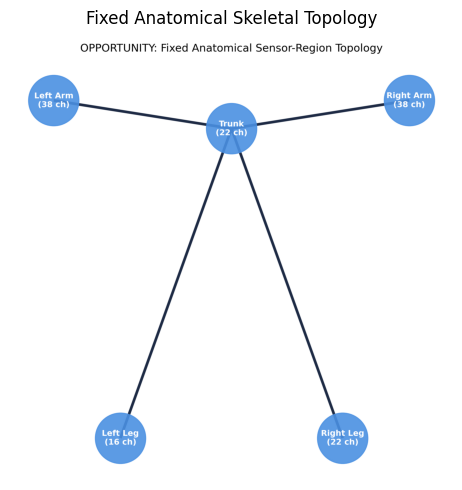

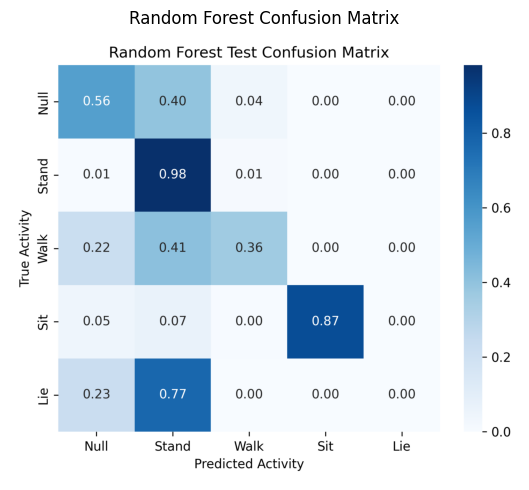

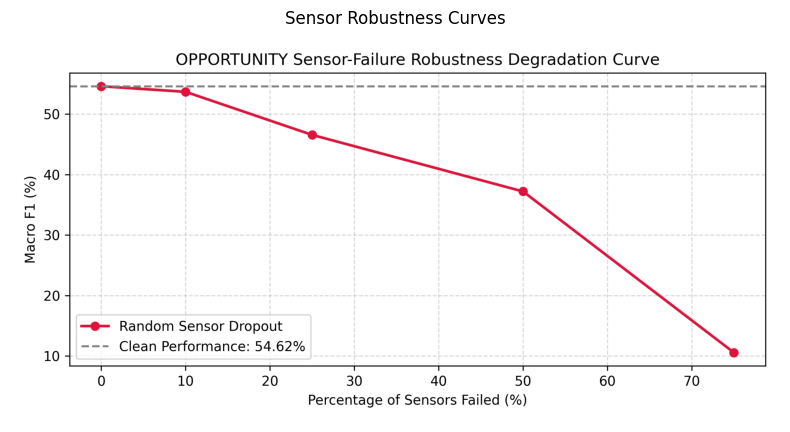

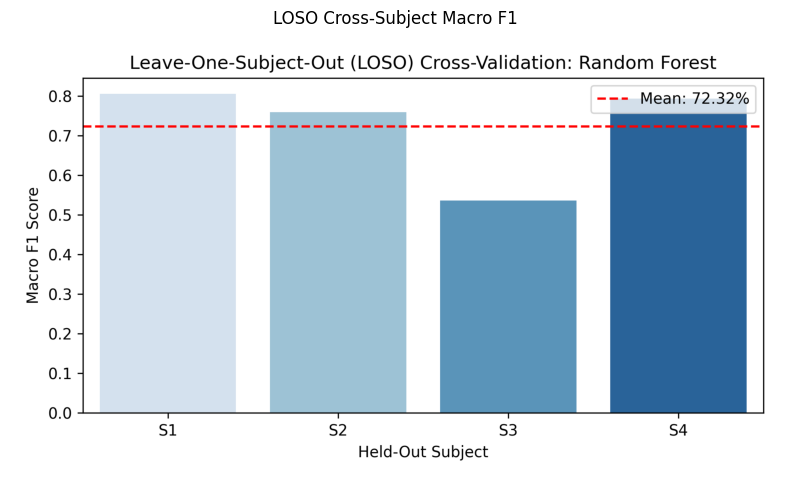

In [6]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

figures_to_display = [
    ("Fixed Anatomical Skeletal Topology", REPO_DIR / "results" / "dataset_inspection" / "body_region_mapping.png"),
    ("Random Forest Confusion Matrix", REPO_DIR / "results" / "baseline" / "random_forest_cm.png"),
    ("Sensor Robustness Curves", REPO_DIR / "results" / "robustness" / "robustness_curves.png"),
    ("LOSO Cross-Subject Macro F1", REPO_DIR / "results" / "loso" / "loso_random_forest_f1.png"),
]

for title, fig_path in figures_to_display:
    if fig_path.exists():
        plt.figure(figsize=(8, 5))
        img = mpimg.imread(str(fig_path))
        plt.imshow(img)
        plt.title(title, fontsize=12, pad=10)
        plt.axis("off")
        plt.tight_layout()
        plt.show()
    else:
        print(f"Figure not yet generated: {fig_path.name}")